In [1]:
# ============================================================
# 강판 표면 결함 분류 - 범주화 컬럼 추가 통합 버전
# ============================================================
# 기반: gpt_claude.ipynb (5-Fold 튜닝, 소프트 보팅, 클래스별 확률 보정,
#       부트스트랩 신뢰구간, Permutation Importance, 재학습/예측 함수)
#
# [이번에 추가한 것] 범주화할래.ipynb 의 EDA 결과를 반영한 구간 변수
#   - 클래스별 중앙값/분포가 뚜렷하게 갈리는 변수만 골라 구간을 나눔
#   - 구간 경계는 EDA 표에서 클래스가 갈리는 지점으로 설정
#       Thickness_Group    : K_Scatch 99% ≤40 / Stains 98.6% 40~60 / Z_Scratch 89.5% 60~80
#                            / Dirtiness 61.8% 80~150  (범주화할래.ipynb 마지막 셀)
#       Conveyer_Group     : Stains 1354~1362(SD 1.5), Z_Scratch 중앙 1356, K_Scatch 1362
#                            vs Bumps 1624, Pastry 1648
#       Area_Group         : Stains 최대 86 / K_Scatch 중앙 6281 / 나머지 120~210
#       Outside_X_Group    : K_Scatch 중앙 0.113 vs 나머지 ≤0.011
#       Orientation_Group  : K_Scatch·Stains 음수, Pastry 0.667·Dirtiness 0.800
#       Edges_Y_Group      : K_Scatch 중앙 0.474 vs 나머지 0.93~1.0 (Pastry는 거의 1.0)
#       Min_Lum_Group      : K_Scatch 중앙 41 / Stains 115(SD 8.6)
#       Square_Group       : Dirtiness 0.194 / Pastry 0.333 / Bumps·Stains 0.70~0.75
#       Edges_X_Group      : Stains 중앙 1.0 / Dirtiness 0.290
#       Steel_Thickness    : 강종 × 두께구간 조합 (Z_Scratch = A300 90% + 60~80 89.5%)
#   - 트리 모델용으로 순서가 있는 정수 코드(0, 1, 2, ...)로 넣고, 원본 연속형도 그대로 유지
#   - 범주화 컬럼 효과를 반복 교차검증으로 확인하고, 테스트에서도
#     "범주화 컬럼만 뺀 같은 모델"과 비교
#
# [주의] 구간 경계는 전체 데이터(테스트 포함) EDA를 보고 정했으므로
#        테스트 점수가 아주 약간 낙관적일 수 있다. 경계가 몇 개뿐이고 클래스 차이가
#        매우 큰 지점이라 영향은 작지만, 보고 시 함께 적어 두는 것이 좋다.
# ============================================================

In [2]:
# ============================================================
# 0. 라이브러리 및 설정
# ============================================================

import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

from scipy.stats import chi2_contingency
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    RandomizedSearchCV,
    cross_val_score,
    cross_val_predict,
)
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

plt.rcParams["font.family"] = "Malgun Gothic"   # macOS: "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
DATA_PATH = "steel_plates_faults.csv"
N_ITER = 20            # 모델별 무작위 탐색 조합 수 (시간이 부족하면 줄이기)

# True  : 범주화 컬럼을 항상 사용 (요청 사항)
# False : 파생변수처럼 교차검증 결과로 사용 여부를 자동 결정
FORCE_BINNED = True

STEEL_COLS = ["TypeOfSteel_A300", "TypeOfSteel_A400"]
FAULT_COLS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
              "Dirtiness", "Bumps", "Other_Faults"]
TARGET = "Fault_Type"

LABELS = list(range(len(FAULT_COLS)))
class_to_int = {name: i for i, name in enumerate(FAULT_COLS)}
int_to_class = {i: name for name, i in class_to_int.items()}
STEEL_CODE = {"A300": 0, "A400": 1}


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)


def score_row(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Acc": balanced_accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, labels=LABELS,
                                           average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, labels=LABELS,
                                     average="macro", zero_division=0),
        "Macro F1": macro_f1(y_true, y_pred),
    }


def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if min(table.shape) < 2:
        return 0.0
    chi2 = chi2_contingency(table)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

In [3]:
# ============================================================
# 1. 데이터 불러오기 및 열 병합 (원-핫 구조 검증 포함)
# ============================================================

raw_df = pd.read_csv(DATA_PATH)
print("원본 데이터 크기:", raw_df.shape)
print("결측치:", raw_df.isna().sum().sum(), "/ 중복 행:", raw_df.duplicated().sum())

for cols, label in [(STEEL_COLS, "강종"), (FAULT_COLS, "결함 유형")]:
    missing = [c for c in cols if c not in raw_df.columns]
    if missing:
        raise ValueError(f"{label} 열이 없습니다: {missing}")
    if not raw_df[cols].isin([0, 1]).all().all():
        raise ValueError(f"{label} 열은 0 또는 1이어야 합니다.")
    if not (raw_df[cols].sum(axis=1) == 1).all():
        raise ValueError(f"{label}이(가) 정확히 하나로 정해지지 않는 행이 있습니다.")


def merge_columns(data: pd.DataFrame) -> pd.DataFrame:
    """강종 2열 → Steel_Type, 결함 7열 → Fault_Type (결함 열이 없으면 강종만)"""
    out = data.copy()
    if set(STEEL_COLS).issubset(out.columns):
        pos = out.columns.get_loc("TypeOfSteel_A300")
        steel = np.where(out["TypeOfSteel_A300"] == 1, "A300", "A400")
        out = out.drop(columns=STEEL_COLS)
        out.insert(pos, "Steel_Type", steel)
    if set(FAULT_COLS).issubset(out.columns):
        out[TARGET] = out[FAULT_COLS].idxmax(axis=1)
        out = out.drop(columns=FAULT_COLS)
    return out


df = merge_columns(raw_df)
print("병합 후 데이터 크기:", df.shape)

print("\n[결함 유형 분포]")
display(df[TARGET].value_counts().reindex(FAULT_COLS).to_frame("count"))

원본 데이터 크기: (1941, 34)
결측치: 0 / 중복 행: 0
병합 후 데이터 크기: (1941, 27)

[결함 유형 분포]


,count
Fault_Type,
Pastry,158
Z_Scratch,190
K_Scatch,391
Stains,72
Dirtiness,55
Bumps,402
Other_Faults,673


In [4]:
# ============================================================
# 2. 강종 - 결함 유형 관계 (카이제곱 검정, Cramér's V)
# ============================================================

ct = pd.crosstab(df[TARGET], df["Steel_Type"]).reindex(FAULT_COLS)
chi2, p_value, dof, _ = chi2_contingency(ct)
cv_steel = np.sqrt(chi2 / (len(df) * (min(ct.shape) - 1)))

print("\n[결함 유형 × 강종]")
display(ct)
print(f"Chi2 = {chi2:.1f}, df = {dof}, p = "
      f"{'<0.001' if p_value < 0.001 else round(p_value, 4)}, Cramér's V = {cv_steel:.3f}")


[결함 유형 × 강종]


Steel_Type,A300,A400
Fault_Type,,
Pastry,49,109
Z_Scratch,172,18
K_Scatch,1,390
Stains,1,71
Dirtiness,9,46
Bumps,279,123
Other_Faults,266,407


Chi2 = 667.0, df = 6, p = <0.001, Cramér's V = 0.586


In [5]:
# ============================================================
# 3. 범주화(구간) 정의 - 범주화할래.ipynb EDA 결과 반영
# ============================================================
# pd.cut 은 오른쪽 경계 포함: (40, 60] → 50, 60 포함
# 양 끝을 -inf / inf 로 두어 새 데이터가 범위를 벗어나도 결측이 생기지 않게 함
# ============================================================

INF = np.inf
BIN_SPECS = {
    # 새 컬럼명            : (원본 컬럼, 경계, 라벨)
    "Thickness_Group":   ("Steel_Plate_Thickness", [-INF, 40, 60, 80, 150, INF],
                          ["40 이하", "40~60", "60~80", "80~150", "150 초과"]),
    "Conveyer_Group":    ("Length_of_Conveyer", [-INF, 1350, 1365, 1600, INF],
                          ["1350 이하", "1350~1365", "1365~1600", "1600 초과"]),
    "Area_Group":        ("Pixels_Areas", [-INF, 100, 1000, 5000, INF],
                          ["100 이하", "100~1000", "1000~5000", "5000 초과"]),
    "Outside_X_Group":   ("Outside_X_Index", [-INF, 0.02, 0.05, INF],
                          ["0.02 이하", "0.02~0.05", "0.05 초과"]),
    "Orientation_Group": ("Orientation_Index", [-INF, -0.3, 0.3, 0.6, INF],
                          ["-0.3 이하", "-0.3~0.3", "0.3~0.6", "0.6 초과"]),
    "Edges_Y_Group":     ("Edges_Y_Index", [-INF, 0.7, 0.999, INF],
                          ["0.7 이하", "0.7~0.999", "1.0"]),
    "Min_Lum_Group":     ("Minimum_of_Luminosity", [-INF, 60, 100, INF],
                          ["60 이하", "60~100", "100 초과"]),
    "Square_Group":      ("Square_Index", [-INF, 0.3, 0.6, INF],
                          ["0.3 이하", "0.3~0.6", "0.6 초과"]),
    "Edges_X_Group":     ("Edges_X_Index", [-INF, 0.5, 0.9, INF],
                          ["0.5 이하", "0.5~0.9", "0.9 초과"]),
}
N_THICK = len(BIN_SPECS["Thickness_Group"][2])
BINNED_FEATURES = list(BIN_SPECS) + ["Steel_Thickness"]
EXTRA_FEATURES = ["Luminosity_Range", "Aspect_Ratio", "Perimeter_Area_Ratio"]


def add_binned(out: pd.DataFrame) -> pd.DataFrame:
    """구간 변수를 순서형 정수 코드로 추가 (Steel_Type은 이미 0/1로 변환된 상태)"""
    for new_col, (src, bins, _) in BIN_SPECS.items():
        out[new_col] = pd.cut(out[src], bins=bins, labels=False).astype(int)
    # 강종 × 두께구간: A300 → 0~4, A400 → 5~9
    out["Steel_Thickness"] = out["Steel_Type"] * N_THICK + out["Thickness_Group"]
    return out


def build_features(data: pd.DataFrame, use_extra: bool, use_binned: bool) -> pd.DataFrame:
    out = data.drop(columns=[TARGET], errors="ignore").copy()
    out["Steel_Type"] = out["Steel_Type"].map(STEEL_CODE)
    if out["Steel_Type"].isna().any():
        raise ValueError("Steel_Type에 A300 / A400 이외의 값이 있습니다.")

    if use_extra:
        x_len = out["X_Maximum"] - out["X_Minimum"] + 1
        y_len = out["Y_Maximum"] - out["Y_Minimum"] + 1
        out["Luminosity_Range"] = out["Maximum_of_Luminosity"] - out["Minimum_of_Luminosity"]
        out["Aspect_Ratio"] = x_len / y_len
        out["Perimeter_Area_Ratio"] = (
            (out["X_Perimeter"] + out["Y_Perimeter"]) / out["Pixels_Areas"]
        )
    if use_binned:
        out = add_binned(out)
    return out


def binned_labels(data: pd.DataFrame) -> pd.DataFrame:
    """확인용: 구간을 사람이 읽을 수 있는 라벨로"""
    out = pd.DataFrame(index=data.index)
    for new_col, (src, bins, labels) in BIN_SPECS.items():
        out[new_col] = pd.cut(data[src], bins=bins, labels=labels)
    out["Steel_Thickness"] = data["Steel_Type"].astype(str) + "_" + out["Thickness_Group"].astype(str)
    return out


y_all = df[TARGET].map(class_to_int).to_numpy()

In [6]:
# ============================================================
# 4. 개발 / 테스트 분할 (80 / 20, 층화)
# ============================================================

idx_dev, idx_test = train_test_split(
    np.arange(len(df)), test_size=0.20, stratify=y_all, random_state=RANDOM_STATE
)
y_dev, y_test = y_all[idx_dev], y_all[idx_test]
print(f"\n개발: {len(idx_dev)}개 / 테스트: {len(idx_test)}개")

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)


개발: 1552개 / 테스트: 389개


In [7]:
# ============================================================
# 5. 범주화 컬럼 점검 (개발 데이터만 사용)
# ============================================================
# 구간별 클래스 구성이 개발 데이터에서도 EDA와 같은 모양인지,
# 구간 변수 하나만으로 결함 유형과 얼마나 연관되는지(Cramér's V) 확인한다.
# ============================================================

dev_labels = binned_labels(df.iloc[idx_dev])
dev_target = df.iloc[idx_dev][TARGET]

bin_check = []
for col in BINNED_FEATURES:
    src = BIN_SPECS[col][0] if col in BIN_SPECS else "Steel_Type × Thickness"
    sizes = dev_labels[col].value_counts()
    bin_check.append({
        "범주화 컬럼": col,
        "원본 컬럼": src,
        "구간 수": dev_labels[col].nunique(),
        "최소 구간 크기": int(sizes.min()),
        "Cramér's V": cramers_v(dev_labels[col], dev_target),
    })
bin_check_df = (pd.DataFrame(bin_check)
                .sort_values("Cramér's V", ascending=False).reset_index(drop=True))
print("[범주화 컬럼 - 결함 유형 연관성 (개발 데이터)]")
display(bin_check_df.round(3))

# 연관성이 큰 상위 3개는 구간별 클래스 비율(%)까지 확인
for col in bin_check_df["범주화 컬럼"].head(3):
    print(f"\n[{col}] 구간별 결함 유형 비율(%) - 행 합계 100")
    display(pd.crosstab(dev_labels[col], dev_target, normalize="index")
            .reindex(columns=FAULT_COLS).mul(100).round(1))

[범주화 컬럼 - 결함 유형 연관성 (개발 데이터)]


,범주화 컬럼,원본 컬럼,구간 수,최소 구간 크기,Cramér's V
0,Outside_X_Group,Outside_X_Index,3,126,0.586
1,Min_Lum_Group,Minimum_of_Luminosity,3,360,0.519
2,Thickness_Group,Steel_Plate_Thickness,5,158,0.508
3,Edges_Y_Group,Edges_Y_Index,3,430,0.499
4,Steel_Thickness,Steel_Type × Thickness,9,36,0.493
5,Area_Group,Pixels_Areas,4,140,0.487
6,Orientation_Group,Orientation_Index,4,275,0.383
7,Square_Group,Square_Index,3,280,0.359
8,Conveyer_Group,Length_of_Conveyer,4,25,0.354
9,Edges_X_Group,Edges_X_Index,3,200,0.288



[Outside_X_Group] 구간별 결함 유형 비율(%) - 행 합계 100


Fault_Type,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
Outside_X_Group,,,,,,,
0.02 이하,10.9,11.6,3.9,5.1,3.8,25.9,38.8
0.02~0.05,1.6,14.3,9.5,0.0,0.8,18.3,55.6
0.05 초과,0.0,1.0,87.7,0.0,0.0,1.7,9.6



[Min_Lum_Group] 구간별 결함 유형 비율(%) - 행 합계 100


Fault_Type,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
Min_Lum_Group,,,,,,,
60 이하,7.8,5.0,67.5,0.0,0.6,4.7,14.4
60~100,12.8,12.8,2.0,0.6,2.4,32.2,37.2
100 초과,2.6,9.3,10.6,10.1,4.9,17.4,45.1



[Thickness_Group] 구간별 결함 유형 비율(%) - 행 합계 100


Fault_Type,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
Thickness_Group,,,,,,,
40 이하,5.3,1.2,54.5,0.0,1.8,10.5,26.7
40~60,9.5,0.0,1.3,36.1,0.6,36.1,16.5
60~80,4.3,29.1,0.2,0.0,1.3,30.7,34.3
80~150,23.8,1.0,0.0,0.5,13.1,19.4,42.2
150 초과,7.5,5.7,0.0,0.0,0.0,14.5,72.3


In [8]:
# ============================================================
# 6. 변수 조합 결정 (개발 데이터 반복 교차검증)
# ============================================================
# 원본 / +파생 / +범주화 / +파생+범주화 네 조합을 RF와 LightGBM 두 모델로 비교.
# (RF는 무작위 분할 후보를 쓰고 LightGBM은 히스토그램 분할을 써서
#  구간 변수에 반응하는 방식이 다르므로 둘 다 확인)
# ============================================================

probes = {
    "RF": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "LGBM": LGBMClassifier(objective="multiclass", random_state=RANDOM_STATE,
                           n_jobs=-1, verbose=-1),
}
combos = {
    "원본만": (False, False),
    "원본 + 파생": (True, False),
    "원본 + 범주화": (False, True),
    "원본 + 파생 + 범주화": (True, True),
}

fs_rows = []
for cname, (ue, ub) in combos.items():
    X_tmp = build_features(df, ue, ub).iloc[idx_dev]
    row = {"조합": cname, "변수 수": X_tmp.shape[1]}
    all_scores = []
    for pname, probe in probes.items():
        s = cross_val_score(probe, X_tmp, y_dev, cv=cv_rep, scoring="f1_macro", n_jobs=-1)
        row[f"{pname} 평균"] = s.mean()
        row[f"{pname} SD"] = s.std()
        all_scores.append(s)
    row["두 모델 평균"] = np.mean(np.concatenate(all_scores))
    row["두 모델 SD"] = np.std(np.concatenate(all_scores))
    fs_rows.append(row)

fs_df = pd.DataFrame(fs_rows).set_index("조합")
print("[변수 조합별 CV Macro F1 (5-Fold × 3회)]")
display(fs_df.round(4))

base_mean, base_sd = fs_df.loc["원본만", ["두 모델 평균", "두 모델 SD"]]


def worth_it(name):
    # 평균이 표준편차의 절반 이상 좋아질 때만 채택 (작은 차이는 단순한 쪽)
    return fs_df.loc[name, "두 모델 평균"] - base_mean > 0.5 * base_sd


if FORCE_BINNED:
    USE_BINNED = True
    # 범주화 포함 상태에서 파생변수를 더할지 판단
    gain = (fs_df.loc["원본 + 파생 + 범주화", "두 모델 평균"]
            - fs_df.loc["원본 + 범주화", "두 모델 평균"])
    USE_EXTRA = gain > 0.5 * fs_df.loc["원본 + 범주화", "두 모델 SD"]
else:
    USE_BINNED = worth_it("원본 + 범주화") or worth_it("원본 + 파생 + 범주화")
    USE_EXTRA = worth_it("원본 + 파생") or (USE_BINNED and worth_it("원본 + 파생 + 범주화")
                                          and not worth_it("원본 + 범주화"))

binned_gain = fs_df.loc["원본 + 범주화", "두 모델 평균"] - base_mean
print(f"범주화 컬럼 추가 효과(원본 대비): {binned_gain:+.4f}  (원본 SD {base_sd:.4f})")
print(f"→ 범주화 사용: {USE_BINNED} {'(FORCE_BINNED)' if FORCE_BINNED else ''}"
      f" / 파생변수 사용: {USE_EXTRA}")

X_all = build_features(df, USE_EXTRA, USE_BINNED)
feature_cols = X_all.columns.tolist()
X_dev, X_test = X_all.iloc[idx_dev], X_all.iloc[idx_test]
print(f"최종 입력 변수 {len(feature_cols)}개")

[변수 조합별 CV Macro F1 (5-Fold × 3회)]


,변수 수,RF 평균,RF SD,LGBM 평균,LGBM SD,두 모델 평균,두 모델 SD
조합,,,,,,,
원본만,26,0.7967,0.0252,0.8075,0.0230,0.8021,0.0248
원본 + 파생,29,0.7961,0.0249,0.8121,0.0208,0.8041,0.0243
원본 + 범주화,36,0.7967,0.0232,0.8108,0.0202,0.8037,0.0229
원본 + 파생 + 범주화,39,0.7982,0.0230,0.8105,0.0214,0.8044,0.0231


범주화 컬럼 추가 효과(원본 대비): +0.0016  (원본 SD 0.0248)
→ 범주화 사용: True (FORCE_BINNED) / 파생변수 사용: False
최종 입력 변수 36개


In [9]:
# ============================================================
# 7. 모델 및 탐색 공간
# ============================================================
# 선형/거리 기반 모델은 이전 비교에서 Macro F1이 0.07~0.17 낮아 트리 계열만 사용.
# 범주화 컬럼은 순서형 정수라 트리 모델에 그대로 넣는다.
# ============================================================

models = {
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    "Extra Trees": ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=1),
    "LightGBM": LGBMClassifier(objective="multiclass", random_state=RANDOM_STATE,
                               n_jobs=1, verbose=-1),
    "CatBoost": CatBoostClassifier(loss_function="MultiClass", random_seed=RANDOM_STATE,
                                   verbose=0, allow_writing_files=False, thread_count=1),
}

param_spaces = {
    "Random Forest": {
        "n_estimators": [300, 500, 700],
        "max_depth": [None, 10, 15, 20, 30],
        "min_samples_split": [2, 5, 9],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.3, 0.5, 0.8],
        "class_weight": [None, "balanced", "balanced_subsample"],
    },
    "Extra Trees": {
        "n_estimators": [300, 500, 700],
        "max_depth": [None, 10, 15, 20, 30],
        "min_samples_split": [2, 5, 9],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.3, 0.5, 0.8],
        "class_weight": [None, "balanced", "balanced_subsample"],
    },
    "LightGBM": {
        "n_estimators": [200, 400, 700, 1000],
        "learning_rate": [0.02, 0.03, 0.05, 0.1],
        "num_leaves": [7, 15, 22, 31],
        "max_depth": [-1, 5, 7, 10],
        "min_child_samples": [5, 10, 20, 33],
        "subsample": [0.6, 0.8, 1.0],
        "subsample_freq": [1],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "reg_lambda": [0, 0.01, 1, 5],
        "class_weight": [None, "balanced"],
    },
    "CatBoost": {
        "iterations": [300, 500, 700],
        "depth": [4, 5, 6, 7],
        "learning_rate": [0.03, 0.05, 0.1],
        "l2_leaf_reg": [1, 3, 5, 7],
        "auto_class_weights": [None, "Balanced", "SqrtBalanced"],
    },
}

In [10]:
# ============================================================
# 8. 하이퍼파라미터 튜닝 (개발 데이터 5-Fold, Macro F1)
# ============================================================

tuned = {}
tuning_rows = []

for name, model in models.items():
    print(f"\n{name} 튜닝 중... ({N_ITER}개 조합 × 5-Fold)")
    start = time.time()
    search = RandomizedSearchCV(
        model, param_spaces[name], n_iter=N_ITER, scoring="f1_macro",
        cv=cv5, random_state=RANDOM_STATE, n_jobs=-1, refit=False,
    )
    search.fit(X_dev, y_dev)
    tuned[name] = clone(model).set_params(**search.best_params_)

    tuning_rows.append({
        "Model": name,
        "CV Macro F1": search.best_score_,
        "CV SD": search.cv_results_["std_test_score"][search.best_index_],
        "Best Params": search.best_params_,
        "Time(s)": round(time.time() - start, 1),
    })
    print(f"  CV Macro F1 = {search.best_score_:.4f} | {search.best_params_}")

tuning_df = (pd.DataFrame(tuning_rows)
             .sort_values("CV Macro F1", ascending=False).reset_index(drop=True))
print("\n[튜닝 결과]")
display(tuning_df)


Random Forest 튜닝 중... (20개 조합 × 5-Fold)
  CV Macro F1 = 0.8024 | {'n_estimators': 700, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': None, 'class_weight': None}

Extra Trees 튜닝 중... (20개 조합 × 5-Fold)
  CV Macro F1 = 0.8168 | {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 20, 'class_weight': 'balanced'}

LightGBM 튜닝 중... (20개 조합 × 5-Fold)
  CV Macro F1 = 0.8177 | {'subsample_freq': 1, 'subsample': 0.8, 'reg_lambda': 5, 'num_leaves': 15, 'n_estimators': 1000, 'min_child_samples': 10, 'max_depth': 10, 'learning_rate': 0.03, 'colsample_bytree': 0.8, 'class_weight': 'balanced'}

CatBoost 튜닝 중... (20개 조합 × 5-Fold)
  CV Macro F1 = 0.8156 | {'learning_rate': 0.05, 'l2_leaf_reg': 3, 'iterations': 700, 'depth': 7, 'auto_class_weights': 'SqrtBalanced'}

[튜닝 결과]


,Model,CV Macro F1,CV SD,Best Params,Time(s)
0,LightGBM,0.817697,0.010829,"{'subsample_freq': 1, 'subsample': 0.8, 'reg_l...",10.1
1,Extra Trees,0.816822,0.014559,"{'n_estimators': 300, 'min_samples_split': 5, ...",8.1
2,CatBoost,0.815569,0.020017,"{'learning_rate': 0.05, 'l2_leaf_reg': 3, 'ite...",191.0
3,Random Forest,0.802411,0.020988,"{'n_estimators': 700, 'min_samples_split': 2, ...",16.8


In [11]:
# ============================================================
# 9. Out-of-fold 확률 예측 + 앙상블 후보 + 클래스별 확률 보정
# ============================================================

oof = {}
for name, est in tuned.items():
    oof[name] = cross_val_predict(
        clone(est), X_dev, y_dev, cv=cv5, method="predict_proba", n_jobs=-1
    )


def tune_class_scale(P, y, grid=np.round(np.arange(0.5, 3.01, 0.1), 2), n_rounds=3):
    """
    예측 확률에 클래스별 배율을 곱해 argmax 했을 때 Macro F1이 최대가 되는 배율 탐색.
    배율 > 1 이면 그 클래스를 더 자주 예측(재현율↑ 정밀도↓), < 1 이면 반대.
    """
    w = np.ones(P.shape[1])
    best = macro_f1(y, P.argmax(axis=1))
    for _ in range(n_rounds):
        improved = False
        for k in range(P.shape[1]):
            for g in grid:
                trial = w.copy()
                trial[k] = g
                s = macro_f1(y, (P * trial).argmax(axis=1))
                if s > best + 1e-9:
                    best, w, improved = s, trial, True
        if not improved:
            break
    return w, best


ranked = tuning_df["Model"].tolist()
candidates = {name: [name] for name in ranked}
candidates["앙상블(상위 2)"] = ranked[:2]
candidates["앙상블(상위 3)"] = ranked[:3]
candidates["앙상블(전체 4)"] = ranked

cand_rows = []
cand_scale = {}
for cname, members in candidates.items():
    P = np.mean([oof[m] for m in members], axis=0)
    raw = macro_f1(y_dev, P.argmax(axis=1))
    w, scaled = tune_class_scale(P, y_dev)
    cand_scale[cname] = w
    cand_rows.append({"Candidate": cname, "OOF Macro F1": raw,
                      "OOF Macro F1 (확률 보정)": scaled})

cand_df = (pd.DataFrame(cand_rows)
           .sort_values("OOF Macro F1 (확률 보정)", ascending=False).reset_index(drop=True))
print("\n[후보별 Out-of-fold 성능]")
display(cand_df.round(4))


[후보별 Out-of-fold 성능]


,Candidate,OOF Macro F1,OOF Macro F1 (확률 보정)
0,앙상블(상위 3),0.8279,0.8355
1,앙상블(전체 4),0.8289,0.8346
2,LightGBM,0.8179,0.8314
3,앙상블(상위 2),0.8240,0.8313
4,Random Forest,0.8032,0.8283
5,Extra Trees,0.8170,0.8262
6,CatBoost,0.8152,0.8260


In [12]:
# ============================================================
# 10. 최종 후보 선택
# ============================================================
# 보정 이득이 0.005 미만이면 보정 없이 사용한다.
# ============================================================

class ScaledSoftVoting(BaseEstimator, ClassifierMixin):
    """여러 모델의 확률 평균 + 클래스별 배율 보정"""

    def __init__(self, estimators, class_scale=None):
        self.estimators = estimators
        self.class_scale = class_scale

    def fit(self, X, y):
        self.estimators_ = [clone(e).fit(X, y) for e in self.estimators]
        self.classes_ = np.unique(y)
        return self

    def predict_proba(self, X):
        P = np.mean([e.predict_proba(X) for e in self.estimators_], axis=0)
        if self.class_scale is not None:
            P = P * np.asarray(self.class_scale)
            P = P / P.sum(axis=1, keepdims=True)
        return P

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


best_row = cand_df.iloc[0]
best_cand = best_row["Candidate"]
use_scale = (best_row["OOF Macro F1 (확률 보정)"] - best_row["OOF Macro F1"]) >= 0.005
final_scale = cand_scale[best_cand] if use_scale else None

print("\n최종 후보:", best_cand, "| 구성:", candidates[best_cand])
print("확률 보정 사용:", use_scale)
if use_scale:
    display(pd.Series(final_scale, index=FAULT_COLS, name="클래스 배율").round(2))

final_model = ScaledSoftVoting(
    [tuned[m] for m in candidates[best_cand]], class_scale=final_scale
).fit(X_dev, y_dev)


최종 후보: 앙상블(상위 3) | 구성: ['LightGBM', 'Extra Trees', 'CatBoost']
확률 보정 사용: True


Pastry          2.5
Z_Scratch       1.1
K_Scatch        1.2
Stains          0.5
Dirtiness       0.5
Bumps           2.6
Other_Faults    1.0
Name: 클래스 배율, dtype: float64

In [13]:
# ============================================================
# 11. 테스트 평가 (마지막 1회)
# ============================================================

y_pred = final_model.predict(X_test)
test_scores = score_row(y_test, y_pred)

print("\n" + "=" * 60)
print(f"최종 테스트 결과 - {best_cand}{' + 확률 보정' if use_scale else ''}"
      f"{' + 범주화 컬럼' if USE_BINNED else ''}")
print("=" * 60)
display(pd.DataFrame([test_scores]).round(4))

rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(1000):
    b = rng.integers(0, len(y_test), len(y_test))
    boot.append(macro_f1(y_test[b], y_pred[b]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"테스트 Macro F1 95% 신뢰구간: [{lo:.3f}, {hi:.3f}]")

print("\n[Classification Report - Test]")
print(classification_report(y_test, y_pred, labels=LABELS,
                            target_names=FAULT_COLS, digits=4, zero_division=0))

# 참고용: 다른 후보들의 테스트 성능 (이것을 보고 선택을 바꾸지 않는다)
ref_rows = []
for cname, members in candidates.items():
    m = ScaledSoftVoting([tuned[x] for x in members]).fit(X_dev, y_dev)
    ref_rows.append({"Candidate": cname, "Test Macro F1 (보정 없음)":
                     macro_f1(y_test, m.predict(X_test))})
print("[참고] 후보별 테스트 Macro F1")
display(pd.DataFrame(ref_rows).round(4))


최종 테스트 결과 - 앙상블(상위 3) + 확률 보정 + 범주화 컬럼


,Accuracy,Balanced Acc,Macro Precision,Macro Recall,Macro F1
0,0.7841,0.8358,0.8085,0.8358,0.8099


테스트 Macro F1 95% 신뢰구간: [0.759, 0.850]

[Classification Report - Test]
              precision    recall  f1-score   support

      Pastry     0.5385    0.8750    0.6667        32
   Z_Scratch     0.9231    0.9474    0.9351        38
    K_Scatch     0.9872    0.9872    0.9872        78
      Stains     0.9286    0.9286    0.9286        14
   Dirtiness     0.8000    0.7273    0.7619        11
       Bumps     0.6168    0.8148    0.7021        81
Other_Faults     0.8652    0.5704    0.6875       135

    accuracy                         0.7841       389
   macro avg     0.8085    0.8358    0.8099       389
weighted avg     0.8171    0.7841    0.7839       389

[참고] 후보별 테스트 Macro F1


,Candidate,Test Macro F1 (보정 없음)
0,LightGBM,0.8184
1,Extra Trees,0.8124
2,CatBoost,0.8099
3,Random Forest,0.8169
4,앙상블(상위 2),0.8315
5,앙상블(상위 3),0.8288
6,앙상블(전체 4),0.8217


In [14]:
# ============================================================
# 12. [참고] 범주화 컬럼 유무 비교 (같은 모델 구성 · 같은 파라미터 · 같은 보정)
# ============================================================
# 범주화 컬럼만 빼고 나머지를 모두 동일하게 둔 모델과 비교한다.
# 파라미터는 범주화 포함 데이터로 튜닝한 값이라 '빼는 쪽'이 약간 불리할 수 있다.
# 같은 테스트 행에서 짝지어 부트스트랩하므로 차이의 신뢰구간을 직접 볼 수 있다.
# ============================================================

if USE_BINNED:
    keep_cols = [c for c in feature_cols if c not in BINNED_FEATURES]
    no_bin_model = ScaledSoftVoting(
        [tuned[m] for m in candidates[best_cand]], class_scale=final_scale
    ).fit(X_dev[keep_cols], y_dev)
    y_pred_nb = no_bin_model.predict(X_test[keep_cols])

    diff_boot = []
    for _ in range(1000):
        b = rng.integers(0, len(y_test), len(y_test))
        diff_boot.append(macro_f1(y_test[b], y_pred[b]) - macro_f1(y_test[b], y_pred_nb[b]))
    d_lo, d_hi = np.percentile(diff_boot, [2.5, 97.5])

    compare = pd.DataFrame([
        {"모델": "범주화 컬럼 포함", **score_row(y_test, y_pred)},
        {"모델": "범주화 컬럼 제외", **score_row(y_test, y_pred_nb)},
    ]).set_index("모델")
    display(compare.round(4))
    print(f"Macro F1 차이(포함 - 제외) = {compare['Macro F1'].diff(-1).iloc[0]:+.4f}, "
          f"95% 구간 [{d_lo:+.3f}, {d_hi:+.3f}]")
    print("  → 구간이 0을 포함하면 범주화 효과가 있다고 단정하기 어렵다.")

    per_class = pd.DataFrame({
        "F1 (포함)": f1_score(y_test, y_pred, labels=LABELS, average=None, zero_division=0),
        "F1 (제외)": f1_score(y_test, y_pred_nb, labels=LABELS, average=None, zero_division=0),
    }, index=FAULT_COLS)
    per_class["차이"] = per_class["F1 (포함)"] - per_class["F1 (제외)"]
    print("\n[클래스별 F1 비교]")
    display(per_class.round(4))

,Accuracy,Balanced Acc,Macro Precision,Macro Recall,Macro F1
모델,,,,,
범주화 컬럼 포함,0.7841,0.8358,0.8085,0.8358,0.8099
범주화 컬럼 제외,0.7763,0.8299,0.8123,0.8299,0.8082


Macro F1 차이(포함 - 제외) = +0.0016, 95% 구간 [-0.013, +0.015]
  → 구간이 0을 포함하면 범주화 효과가 있다고 단정하기 어렵다.

[클래스별 F1 비교]


,F1 (포함),F1 (제외),차이
Pastry,0.6667,0.6585,0.0081
Z_Scratch,0.9351,0.9231,0.0120
K_Scatch,0.9872,0.9872,0.0000
Stains,0.9286,0.9630,-0.0344
Dirtiness,0.7619,0.7619,0.0000
Bumps,0.7021,0.6943,0.0078
Other_Faults,0.6875,0.6697,0.0178


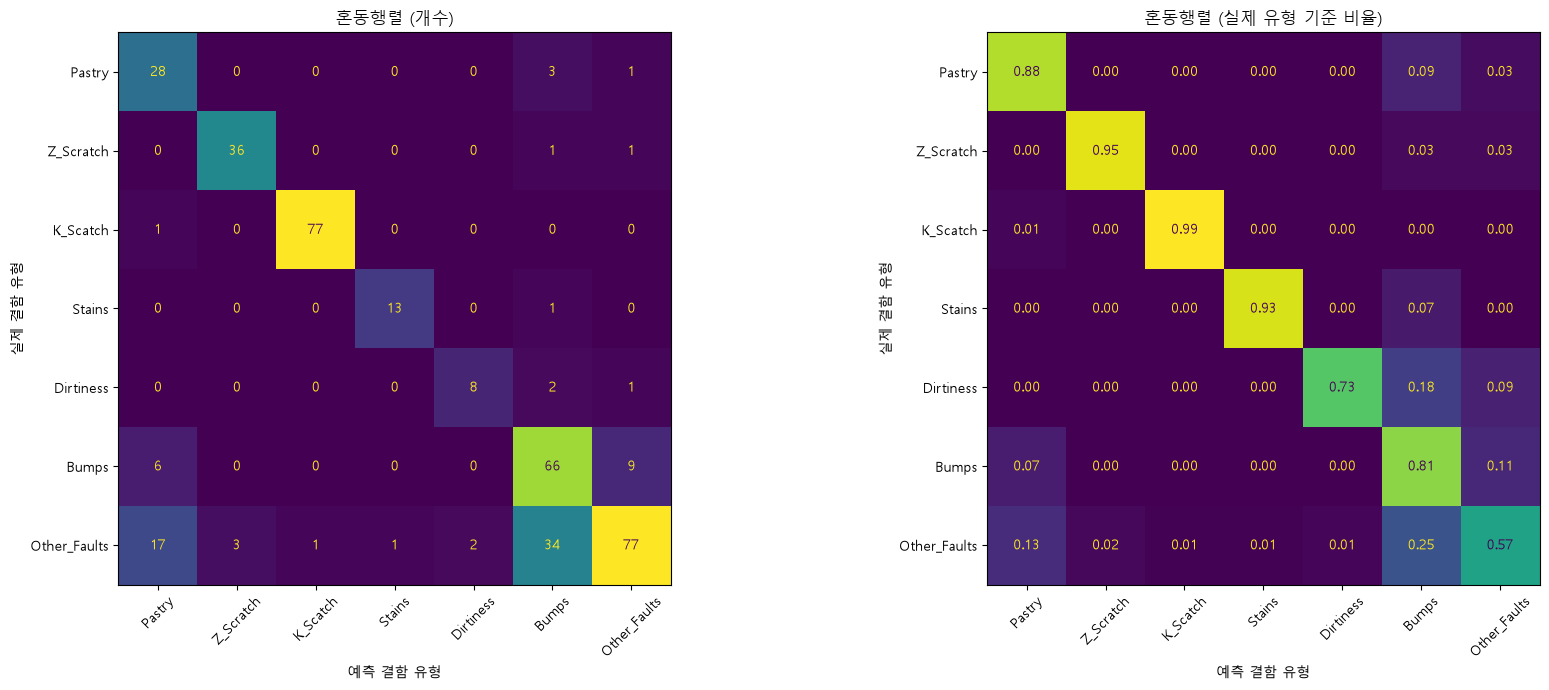


오분류: 84 / 389 (21.59%)


Count
Actual       Predicted          
Other_Faults Bumps            34
             Pastry           17
Bumps        Other_Faults      9
             Pastry            6
Other_Faults Z_Scratch         3
Pastry       Bumps             3
Other_Faults Dirtiness         2
Dirtiness    Bumps             2
Other_Faults K_Scatch          1
K_Scatch     Pastry            1

In [15]:
# ============================================================
# 13. 혼동행렬 및 오분류 분석
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=LABELS),
                       display_labels=FAULT_COLS).plot(
    ax=axes[0], xticks_rotation=45, colorbar=False)
axes[0].set_title("혼동행렬 (개수)")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=LABELS, normalize="true"),
                       display_labels=FAULT_COLS).plot(
    ax=axes[1], xticks_rotation=45, colorbar=False, values_format=".2f")
axes[1].set_title("혼동행렬 (실제 유형 기준 비율)")
for ax in axes:
    ax.set_xlabel("예측 결함 유형")
    ax.set_ylabel("실제 결함 유형")
plt.tight_layout()
plt.show()

test_result = pd.DataFrame({
    "Actual": [int_to_class[i] for i in y_test],
    "Predicted": [int_to_class[i] for i in y_pred],
    "Confidence": final_model.predict_proba(X_test).max(axis=1),
}, index=X_test.index)
misclassified = test_result[test_result["Actual"] != test_result["Predicted"]]

print(f"\n오분류: {len(misclassified)} / {len(y_test)} ({len(misclassified) / len(y_test):.2%})")
display(misclassified.groupby(["Actual", "Predicted"]).size()
        .sort_values(ascending=False).head(10).to_frame("Count"))

,Feature,구분,Importance Mean,Importance SD
0,Length_of_Conveyer,원본,0.0890,0.0237
1,Minimum_of_Luminosity,원본,0.0446,0.0206
2,Steel_Thickness,범주화,0.0306,0.0110
3,Y_Minimum,원본,0.0298,0.0129
4,X_Minimum,원본,0.0256,0.0097
5,Edges_Index,원본,0.0224,0.0090
6,Steel_Plate_Thickness,원본,0.0218,0.0082
7,X_Maximum,원본,0.0218,0.0101
8,Square_Index,원본,0.0142,0.0096
9,Orientation_Index,원본,0.0134,0.0070


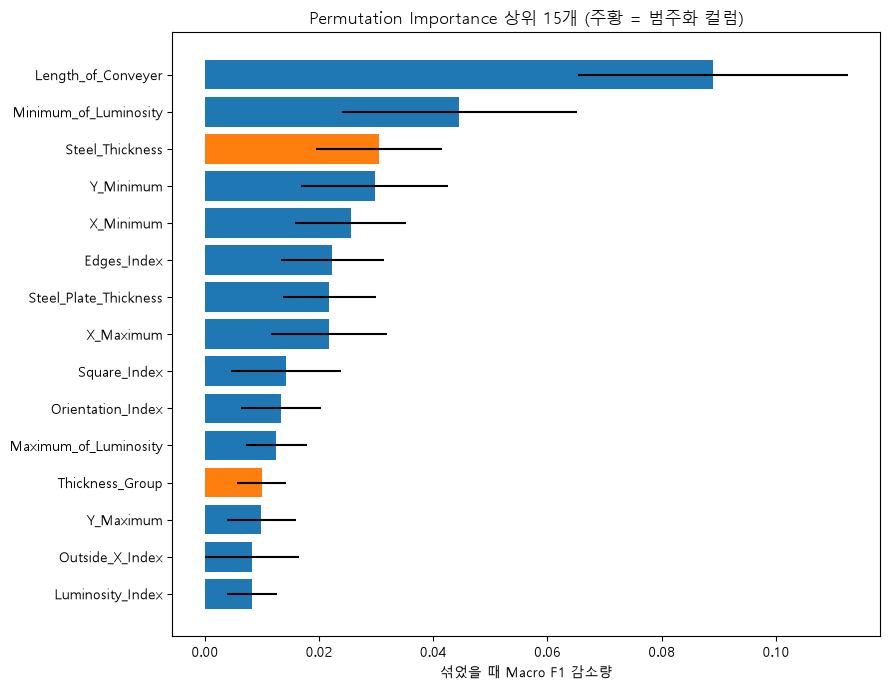


[묶음 Permutation Importance - 원본과 범주화 컬럼을 함께 섞음]


,묶음,Importance Mean,Importance SD
0,Steel_Type + Thickness 묶음,0.2800,0.0135
1,Length_of_Conveyer (+Conveyer_Group),0.1406,0.0211
2,Steel_Plate_Thickness (+Thickness_Group),0.0592,0.0185
3,Minimum_of_Luminosity (+Min_Lum_Group),0.0444,0.0130
4,Square_Index (+Square_Group),0.0221,0.0076
5,Orientation_Index (+Orientation_Group),0.0209,0.0087
6,Edges_Y_Index (+Edges_Y_Group),0.0155,0.0130
7,Outside_X_Index (+Outside_X_Group),0.0139,0.0085
8,Edges_X_Index (+Edges_X_Group),0.0081,0.0067
9,Pixels_Areas (+Area_Group),-0.0020,0.0021


In [16]:
# ============================================================
# 14. 변수 중요도 (Permutation Importance, 테스트 데이터)
# ============================================================
# 범주화 컬럼은 원본과 정보가 겹치므로 하나만 섞으면 다른 쪽이 대신해
# 중요도가 작게 나올 수 있다. 그래서 "원본 + 그 범주화 컬럼"을 함께 섞은
# 묶음 중요도도 같이 본다.
# ============================================================

perm = permutation_importance(final_model, X_test, y_test, scoring="f1_macro",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
importance_df = (pd.DataFrame({
    "Feature": feature_cols,
    "구분": ["범주화" if c in BINNED_FEATURES else
             ("파생" if c in EXTRA_FEATURES else "원본") for c in feature_cols],
    "Importance Mean": perm.importances_mean,
    "Importance SD": perm.importances_std,
}).sort_values("Importance Mean", ascending=False).reset_index(drop=True))
display(importance_df.head(20).round(4))

top = importance_df.head(15).iloc[::-1]
colors = ["tab:orange" if g == "범주화" else "tab:blue" for g in top["구분"]]
plt.figure(figsize=(9, 7))
plt.barh(top["Feature"], top["Importance Mean"], xerr=top["Importance SD"], color=colors)
plt.xlabel("섞었을 때 Macro F1 감소량")
plt.title("Permutation Importance 상위 15개 (주황 = 범주화 컬럼)")
plt.tight_layout()
plt.show()

if USE_BINNED:
    base_f1 = macro_f1(y_test, y_pred)
    groups = {f"{src} (+{new})": [src, new] for new, (src, _, _) in BIN_SPECS.items()}
    groups["Steel_Type + Thickness 묶음"] = ["Steel_Type", "Steel_Plate_Thickness",
                                            "Thickness_Group", "Steel_Thickness"]
    g_rng = np.random.default_rng(RANDOM_STATE)
    g_rows = []
    for gname, cols in groups.items():
        drops = []
        for _ in range(10):
            Xp = X_test.copy()
            perm_idx = g_rng.permutation(len(Xp))
            Xp[cols] = Xp[cols].values[perm_idx]      # 같은 순서로 함께 섞어 관계 유지
            drops.append(base_f1 - macro_f1(y_test, final_model.predict(Xp)))
        g_rows.append({"묶음": gname, "Importance Mean": np.mean(drops),
                       "Importance SD": np.std(drops)})
    print("\n[묶음 Permutation Importance - 원본과 범주화 컬럼을 함께 섞음]")
    display(pd.DataFrame(g_rows).sort_values("Importance Mean", ascending=False)
            .reset_index(drop=True).round(4))

In [17]:
# ============================================================
# 15. 전체 데이터로 재학습 및 저장
# ============================================================

deploy_model = ScaledSoftVoting(
    [tuned[m] for m in candidates[best_cand]], class_scale=final_scale
).fit(X_all, y_all)

joblib.dump({
    "model": deploy_model,
    "candidate": best_cand,
    "members": candidates[best_cand],
    "params": {m: tuned[m].get_params() for m in candidates[best_cand]},
    "class_scale": None if final_scale is None else final_scale.tolist(),
    "use_extra_features": USE_EXTRA,
    "use_binned_features": USE_BINNED,
    "bin_specs": BIN_SPECS,
    "feature_cols": feature_cols,
    "class_names": FAULT_COLS,
    "test_scores": test_scores,
}, "steel_fault_model_binned.joblib")
print("\n저장 완료: steel_fault_model_binned.joblib")


저장 완료: steel_fault_model_binned.joblib


In [18]:
# ============================================================
# 16. 새 데이터 예측 함수
# ============================================================
# 원본 형식(TypeOfSteel_A300/A400) 또는 병합 형식(Steel_Type) 모두 입력 가능.
# ScaledSoftVoting 클래스와 build_features 가 정의된 환경에서 불러와야 한다.
# 구간 경계는 저장된 bin_specs 를 사용하므로 학습 때와 똑같이 나뉜다.
# ============================================================

def predict_faults(new_data: pd.DataFrame,
                   model_path: str = "steel_fault_model_binned.joblib") -> pd.DataFrame:
    global BIN_SPECS
    bundle = joblib.load(model_path)
    names = bundle["class_names"]
    BIN_SPECS = bundle.get("bin_specs", BIN_SPECS)
    merged = merge_columns(new_data.drop(columns=names, errors="ignore"))
    X_new = build_features(merged, bundle["use_extra_features"],
                           bundle.get("use_binned_features", False))[bundle["feature_cols"]]

    proba = bundle["model"].predict_proba(X_new)
    out = pd.DataFrame(proba, columns=[f"prob_{n}" for n in names], index=new_data.index)
    out.insert(0, "predicted_fault", [names[i] for i in proba.argmax(axis=1)])
    out.insert(1, "confidence", proba.max(axis=1))
    return out


demo = predict_faults(raw_df.iloc[idx_test[:5]])
demo.insert(0, "actual_fault", df.iloc[idx_test[:5]][TARGET].values)
print("\n[예측 함수 동작 확인 - 전체 데이터로 재학습한 모델이므로 성능 지표 아님]")
display(demo.round(3))


[예측 함수 동작 확인 - 전체 데이터로 재학습한 모델이므로 성능 지표 아님]


,actual_fault,predicted_fault,confidence,prob_Pastry,prob_Z_Scratch,prob_K_Scatch,prob_Stains,prob_Dirtiness,prob_Bumps,prob_Other_Faults
904,Bumps,Bumps,0.996,0.001,0.000,0.000,0.000,0.0,0.996,0.003
492,K_Scatch,K_Scatch,0.999,0.000,0.000,0.999,0.000,0.0,0.000,0.000
232,Z_Scratch,Z_Scratch,0.985,0.000,0.985,0.000,0.000,0.0,0.003,0.011
1093,Bumps,Bumps,0.944,0.005,0.000,0.001,0.000,0.0,0.944,0.049
803,Stains,Stains,0.992,0.000,0.000,0.000,0.992,0.0,0.002,0.005
